# Day 1 · 이론 2. 이미지 전처리 실습

교안 **7.1~7.7** 연계 · `assets/color_sample.png`, `assets/shadow_document.png`

각 코드를 순서대로 실행하고, `★`로 표시된 값을 변경하여 결과를 비교합니다.

## 7.1 이미지 불러오기와 기본 정보 확인

PIL size (W, H): (512, 512)
NumPy shape (H, W, C): (512, 512, 3)
NumPy dtype: uint8
OpenCV: BGR → RGB로 변환 완료


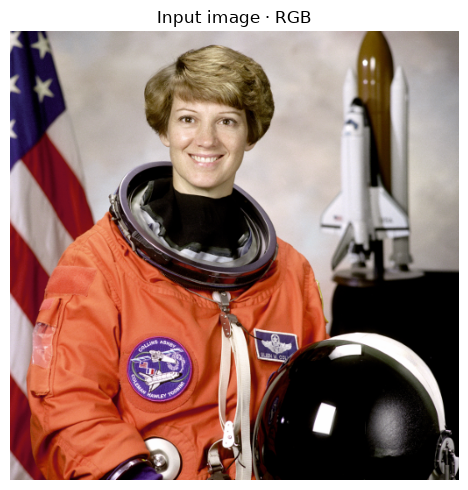

In [1]:
from pathlib import Path
import cv2
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

ASSET_DIR = Path("assets")
if not (ASSET_DIR / "color_sample.png").exists():
    ASSET_DIR = Path("module2_cv_nlp") / "assets"

COLOR_PATH = ASSET_DIR / "color_sample.png"
DOCUMENT_PATH = ASSET_DIR / "shadow_document.png"
assert COLOR_PATH.is_file(), f"컬러 이미지가 없습니다: {COLOR_PATH.resolve()}"
assert DOCUMENT_PATH.is_file(), f"문서 이미지가 없습니다: {DOCUMENT_PATH.resolve()}"

pil_image = Image.open(COLOR_PATH).convert("RGB")
bgr = cv2.imread(str(COLOR_PATH), cv2.IMREAD_COLOR)
assert bgr is not None, "OpenCV에서 컬러 이미지를 읽지 못했습니다."
rgb = cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB)

print("PIL size (W, H):", pil_image.size)
print("NumPy shape (H, W, C):", rgb.shape)
print("NumPy dtype:", rgb.dtype)
print("OpenCV: BGR → RGB로 변환 완료")

fig, ax = plt.subplots(figsize=(5, 5))
ax.imshow(rgb)
ax.set_title("Input image · RGB")
ax.axis("off")
plt.tight_layout()
plt.show()

## 7.2 RGB·Grayscale·HSV 비교

RGB shape: (512, 512, 3)
Grayscale shape: (512, 512)
HSV shape: (512, 512, 3)
RGB [120, 220]: [219, 182, 152]
Grayscale [120, 220]: 190
HSV [120, 220]: [13, 78, 219]
OpenCV 8-bit HSV 범위: H=0~179, S=0~255, V=0~255


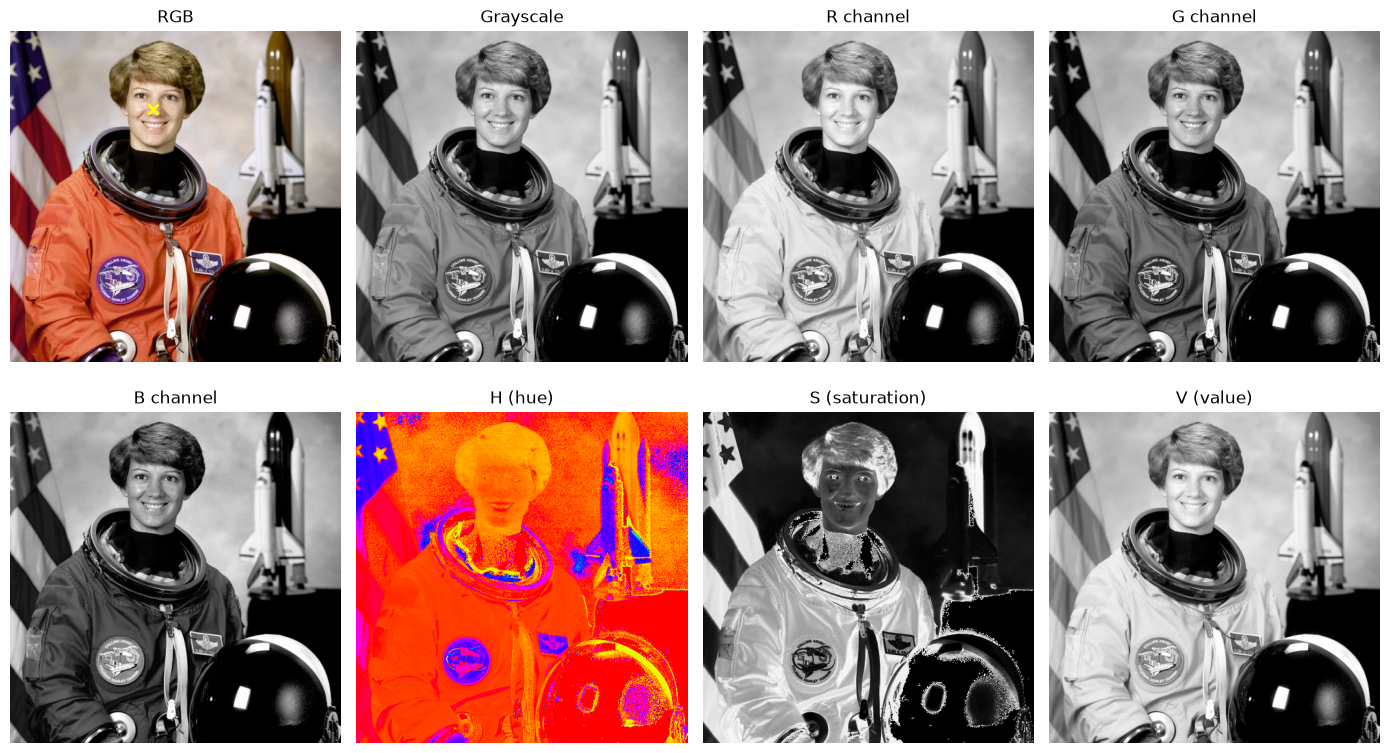

In [2]:
gray = cv2.cvtColor(bgr, cv2.COLOR_BGR2GRAY)
hsv = cv2.cvtColor(bgr, cv2.COLOR_BGR2HSV)
h, s, v = cv2.split(hsv)

# ★ 변경: (120, 220) → (240, 330)
pixel_y, pixel_x = 120, 220
assert 0 <= pixel_y < rgb.shape[0] and 0 <= pixel_x < rgb.shape[1]

print("RGB shape:", rgb.shape)
print("Grayscale shape:", gray.shape)
print("HSV shape:", hsv.shape)
print(f"RGB [{pixel_y}, {pixel_x}]:", rgb[pixel_y, pixel_x].tolist())
print(f"Grayscale [{pixel_y}, {pixel_x}]:", int(gray[pixel_y, pixel_x]))
print(f"HSV [{pixel_y}, {pixel_x}]:", hsv[pixel_y, pixel_x].tolist())
print("OpenCV 8-bit HSV 범위: H=0~179, S=0~255, V=0~255")

items = [
    (rgb, "RGB", None, None),
    (gray, "Grayscale", "gray", (0, 255)),
    (rgb[:, :, 0], "R channel", "gray", (0, 255)),
    (rgb[:, :, 1], "G channel", "gray", (0, 255)),
    (rgb[:, :, 2], "B channel", "gray", (0, 255)),
    (h, "H (hue)", "hsv", (0, 179)),
    (s, "S (saturation)", "gray", (0, 255)),
    (v, "V (value)", "gray", (0, 255)),
]
fig, axs = plt.subplots(2, 4, figsize=(14, 8))
for ax, (arr, title, cmap, limits) in zip(axs.flat, items):
    if cmap is None:
        ax.imshow(arr)
    else:
        ax.imshow(arr, cmap=cmap, vmin=limits[0], vmax=limits[1])
    if title == "RGB":
        ax.scatter([pixel_x], [pixel_y], c="yellow", s=55, marker="x", linewidths=2)
    ax.set_title(title)
    ax.axis("off")
plt.tight_layout()
plt.show()

## 7.3 Resize와 보간법 비교

**7.3-1 Resize와 종횡비**

원본       : Shape=(512, 512, 3), W/H=1.00
224×224  : Shape=(224, 224, 3), W/H=1.00
320×160  : Shape=(160, 320, 3), W/H=2.00


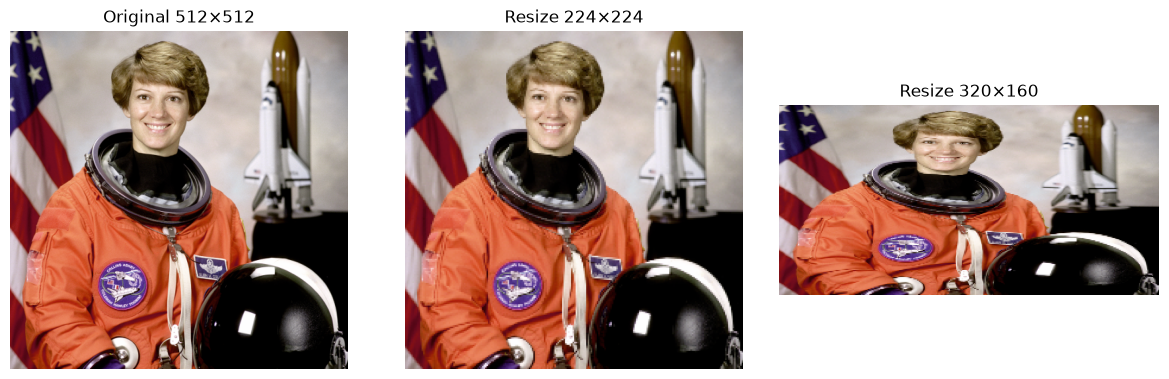

In [3]:
resized = cv2.resize(rgb, (224, 224), interpolation=cv2.INTER_LINEAR)
stretched = cv2.resize(rgb, (320, 160), interpolation=cv2.INTER_LINEAR)

for name, img in [("원본", rgb), ("224×224", resized), ("320×160", stretched)]:
    hh, ww = img.shape[:2]
    print(f"{name:9s}: Shape={img.shape}, W/H={ww/hh:.2f}")

fig, axs = plt.subplots(1, 3, figsize=(12, 3.8))
for ax, arr, title in zip(
    axs, [rgb, resized, stretched],
    ["Original 512×512", "Resize 224×224", "Resize 320×160"]
):
    ax.imshow(arr)
    ax.set_title(title)
    ax.axis("off")
plt.tight_layout()
plt.show()

**7.3-2 Nearest Neighbor와 Bilinear**

원본 Crop: (32, 32, 3)
Nearest 출력: (256, 256, 3)
Bilinear 출력: (256, 256, 3)
두 보간 결과의 평균 절댓값 차이: 3.50 (픽셀값 0~255 기준)


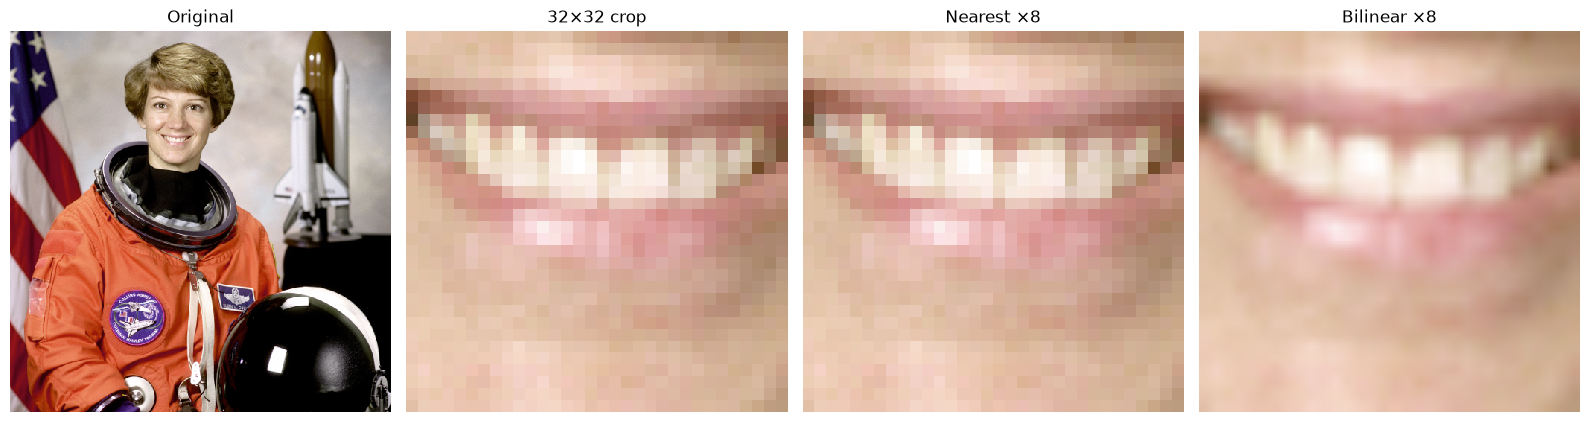

In [4]:
roi = rgb[135:167, 206:238]
assert roi.shape == (32, 32, 3)

# ★ 변경: 8 → 4
zoom_factor = 8
assert isinstance(zoom_factor, int) and zoom_factor >= 1
new_size = (roi.shape[1] * zoom_factor, roi.shape[0] * zoom_factor)

nearest = cv2.resize(roi, new_size, interpolation=cv2.INTER_NEAREST)
bilinear = cv2.resize(roi, new_size, interpolation=cv2.INTER_LINEAR)

print("원본 Crop:", roi.shape)
print("Nearest 출력:", nearest.shape)
print("Bilinear 출력:", bilinear.shape)
mean_abs_diff = np.abs(nearest.astype(np.float32) - bilinear.astype(np.float32)).mean()
print(f"두 보간 결과의 평균 절댓값 차이: {mean_abs_diff:.2f} (픽셀값 0~255 기준)")

fig, axs = plt.subplots(1, 4, figsize=(16, 4.3))
for ax, arr, title in zip(
    axs, [rgb, roi, nearest, bilinear],
    ["Original", "32×32 crop", f"Nearest ×{zoom_factor}", f"Bilinear ×{zoom_factor}"]
):
    ax.imshow(arr, interpolation="nearest")
    ax.set_title(title)
    ax.axis("off")
plt.tight_layout()
plt.show()

## 7.4 Histogram과 Equalization 비교

원본 Grayscale: 평균=115.41, 표준편차=75.12
Equalization 후: 평균=113.91, 표준편차=80.25


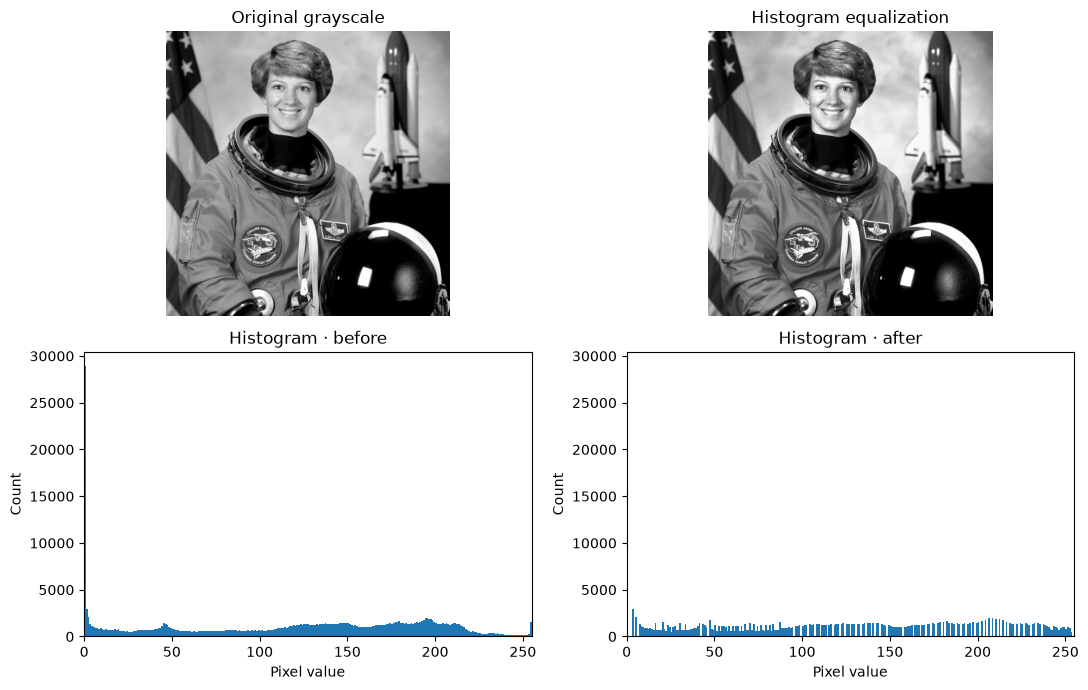

In [5]:
equalized = cv2.equalizeHist(gray)

print(f"원본 Grayscale: 평균={gray.mean():.2f}, 표준편차={gray.std():.2f}")
print(f"Equalization 후: 평균={equalized.mean():.2f}, 표준편차={equalized.std():.2f}")

fig, axs = plt.subplots(2, 2, figsize=(11, 7))
axs[0, 0].imshow(gray, cmap="gray", vmin=0, vmax=255)
axs[0, 0].set_title("Original grayscale")
axs[0, 1].imshow(equalized, cmap="gray", vmin=0, vmax=255)
axs[0, 1].set_title("Histogram equalization")
for ax in axs[0]:
    ax.axis("off")

axs[1, 0].hist(gray.ravel(), bins=256, range=(0, 256))
axs[1, 0].set_title("Histogram · before")
axs[1, 1].hist(equalized.ravel(), bins=256, range=(0, 256))
axs[1, 1].set_title("Histogram · after")
for ax in axs[1]:
    ax.set(xlabel="Pixel value", ylabel="Count", xlim=(0, 255))
plt.tight_layout()
plt.show()

## 7.5 Global·Adaptive Thresholding 비교

Global 기준(T=150) 대비 변경 픽셀 수: 0
Adaptive 기준(block=31) 대비 변경 픽셀 수: 0


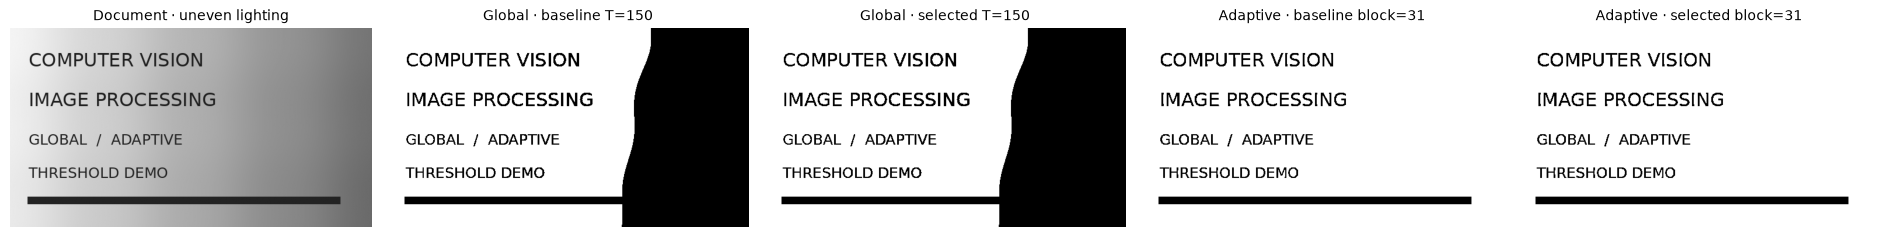

In [6]:
document = cv2.imread(str(DOCUMENT_PATH), cv2.IMREAD_GRAYSCALE)
assert document is not None and document.dtype == np.uint8

BASE_GLOBAL_T = 150
BASE_BLOCK_SIZE = 31
C = 10

# ★ 변경: global_t 150 → 190 / block_size 31 → 51 (하나씩 변경)
global_t = 150
block_size = 31
assert 0 <= global_t <= 255
assert block_size >= 3 and block_size % 2 == 1, "block_size는 3 이상의 홀수여야 합니다."

_, global_before = cv2.threshold(document, BASE_GLOBAL_T, 255, cv2.THRESH_BINARY)
_, global_after = cv2.threshold(document, global_t, 255, cv2.THRESH_BINARY)
adaptive_before = cv2.adaptiveThreshold(
    document, 255, cv2.ADAPTIVE_THRESH_GAUSSIAN_C,
    cv2.THRESH_BINARY, BASE_BLOCK_SIZE, C
)
adaptive_after = cv2.adaptiveThreshold(
    document, 255, cv2.ADAPTIVE_THRESH_GAUSSIAN_C,
    cv2.THRESH_BINARY, block_size, C
)

print(f"Global 기준(T={BASE_GLOBAL_T}) 대비 변경 픽셀 수: {np.count_nonzero(global_before != global_after):,}")
print(f"Adaptive 기준(block={BASE_BLOCK_SIZE}) 대비 변경 픽셀 수: {np.count_nonzero(adaptive_before != adaptive_after):,}")

items = [
    (document, "Document · uneven lighting"),
    (global_before, "Global · baseline T=150"),
    (global_after, f"Global · selected T={global_t}"),
    (adaptive_before, "Adaptive · baseline block=31"),
    (adaptive_after, f"Adaptive · selected block={block_size}"),
]
fig, axs = plt.subplots(1, 5, figsize=(19, 3.4))
for ax, (arr, title) in zip(axs, items):
    ax.imshow(arr, cmap="gray", vmin=0, vmax=255)
    ax.set_title(title, fontsize=10)
    ax.axis("off")
plt.tight_layout()
plt.show()

## 7.6 Flip과 Rotation 비교

원본 Shape: (512, 512, 3)
반전 Shape: (512, 512, 3)
회전 Shape: (512, 512, 3)


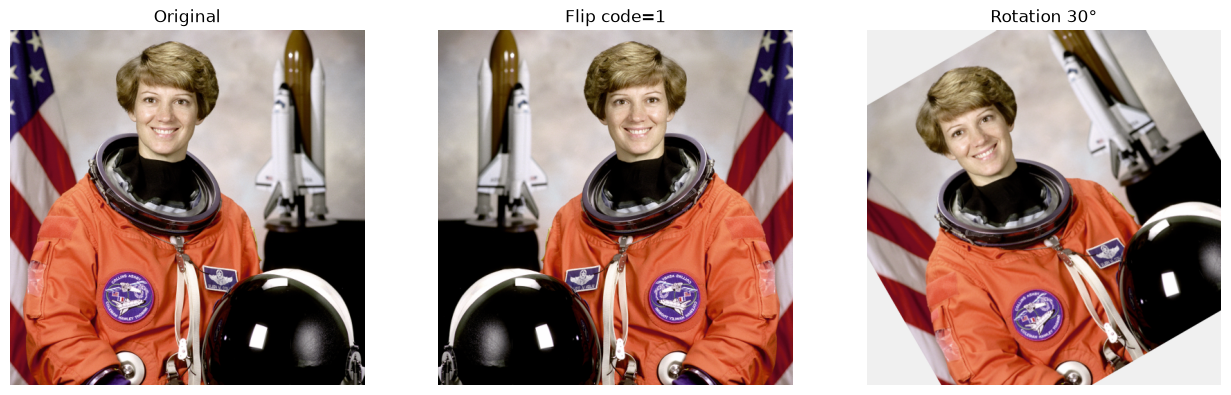

In [7]:
# ★ 변경: 1(좌우) → 0(상하)
flip_code = 1
# ★ 변경: 30 → 45 (도)
angle = 30

flipped = cv2.flip(rgb, flip_code)
H, W = rgb.shape[:2]
rotation_matrix = cv2.getRotationMatrix2D((W / 2, H / 2), angle, 1.0)
rotated = cv2.warpAffine(
    rgb, rotation_matrix, (W, H),
    flags=cv2.INTER_LINEAR,
    borderMode=cv2.BORDER_CONSTANT,
    borderValue=(240, 240, 240)
)

print("원본 Shape:", rgb.shape)
print("반전 Shape:", flipped.shape)
print("회전 Shape:", rotated.shape)

fig, axs = plt.subplots(1, 3, figsize=(13, 4))
for ax, arr, title in zip(
    axs, [rgb, flipped, rotated],
    ["Original", f"Flip code={flip_code}", f"Rotation {angle}°"]
):
    ax.imshow(arr)
    ax.set_title(title)
    ax.axis("off")
plt.tight_layout()
plt.show()